# 2 — Withhold locations, train on a merged graph, predict two ways

Out-of-sample embedding: some locations have no features. `build_graph` merges **locations, not
features** — the node set is `positions ∪ query_positions`, the added rows get a `fill` substitute
in `x`, keep their truth in `y`, and receive messages without sending any (`input_mask=False`).

Three graphs come out of one date:

|Graph|Built with|What it can do|
|---|---|---|
|`observed`|`build_graph(p, f)` on the retained rows|in-sample baseline|
|`merged`|`+ query_positions=q, query_features=fq`|train with truth for both parts|
|`blind`|`+ query_positions=q` only|true out-of-sample: `embed` only|

The last sections train on `merged` and predict twice on the **same coarse graph**: once for the
observed rows only, once for every location.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import numpy as np
import torch
from scipy.spatial import cKDTree

from nofe import NOFE, build_graph
from nofe.affinity import affinity_kl_loss

# Resolve paths from the repository layout, not the process cwd: VS Code always starts kernels in
# the workspace folder (`jupyter.notebookFileRoot` is ignored since 2024.4), while `_execute.py`
# runs from `notebooks/`. Walk up from the cwd looking for the repo root, so both agree.
REPO = next(
    (
        ancestor
        for ancestor in (Path.cwd(), *Path.cwd().parents)
        if (ancestor / "pyproject.toml").is_file()
    ),
    None,
)
if REPO is None:
    raise RuntimeError(f"run this notebook from inside the nofe checkout, not {Path.cwd()}")
NOTEBOOKS = REPO / "notebooks"
DATA = NOTEBOOKS / "data"

# The example data is not in Git (21 MB per date), so fail with the fetch command rather than the
# opaque `StopIteration`/`FileNotFoundError` the loader would otherwise raise.
if not (DATA / "2018-01-01.nc").exists():
    raise FileNotFoundError(
        f"missing {DATA / '2018-01-01.nc'}\n"
        "The ERA5 inputs are not committed. Fetch them once with:\n"
        f"  mkdir -p {DATA}\n"
        f"  cp /Volumes/T7-storage/ERA5/data/2018-01-0{{1,2}}.nc {DATA}/"
    )

# The notebooks import the ERA5 helpers straight from the example script, so the loader and the
# globe plot have exactly one implementation in the repo. `era5` is imported after `sys.path` is
# extended, which is why the noqa marker below is needed.
sys.path.insert(0, str(REPO / "examples"))
import era5  # noqa: E402


def kl(on, embedding) -> float:
    """Mean KL between a graph's own feature affinities and an embedding of its rows."""
    return float(affinity_kl_loss(on.x, embedding, on.edge_index, on.num_nodes))


def pca_baseline(data, dims: int = 3) -> torch.Tensor:
    """Best linear projection to ``dims`` dimensions: the reference the model has to beat."""
    centred = data.x - data.x.mean(dim=0, keepdim=True)
    _, _, basis = torch.linalg.svd(centred, full_matrices=False)
    return centred @ basis[:dims].T


def knn_agreement(reference: torch.Tensor, candidate: torch.Tensor, k: int = 10) -> float:
    """Mean share of exact k-nearest neighbours two point sets have in common."""
    ref = reference.detach().cpu().numpy()
    cand = candidate.detach().cpu().numpy()
    _, ref_nn = cKDTree(ref).query(ref, k=k + 1)
    _, cand_nn = cKDTree(cand).query(cand, k=k + 1)
    shared = [len(set(a) & set(b)) / k for a, b in zip(ref_nn[:, 1:], cand_nn[:, 1:], strict=True)]
    return float(np.mean(shared))


def close(a: torch.Tensor, b: torch.Tensor, rtol: float = 1e-4) -> bool:
    """Relative agreement in units of the embedding's own scale."""
    return bool((a - b).abs().max() <= rtol * a.abs().max())


print("nofe ready; the faiss fallback warning is expected on macOS arm64")


/Users/laueb4818/github/NOFE-pkg/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


nofe ready; the faiss fallback warning is expected on macOS arm64


/Users/laueb4818/github/NOFE-pkg/.venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
# STRIDE=8 is the whole globe at 89 x 180 = 16,020 grid points. Lower the stride for a finer
# grid (4 gives 64,440 nodes, 2 gives the full 258,480-node field).
STRIDE = 8
features, latitudes, longitudes = era5.load_fields(DATA / "2018-01-01.nc", stride=STRIDE)
positions = era5.unit_sphere(latitudes, longitudes)
flat = features.reshape(-1, features.shape[2])
print(
    f"grid {features.shape[0]}x{features.shape[1]} -> {positions.shape[0]} nodes, "
    f"{flat.shape[1]} variables each"
)


grid 89x180 -> 16020 nodes, 11 variables each


## Hold out a random subset of locations

A fixed fraction of grid points is withheld at random, mimicking scattered missing sensors. Any
subset works: the caller decides what to withhold, and there is no holdout fraction anywhere in the
API. The seed is fixed so the split is reproducible.

Random selection spreads the withheld points across the whole globe, which is a fairer test of
out-of-sample prediction than a contiguous gap: nearly every withheld point has observed
neighbours right beside it, rather than sitting in the middle of a large empty region.

In [3]:
def split_nodes(num_nodes: int, fraction: float, seed: int = 0) -> tuple[np.ndarray, np.ndarray]:
    """Boolean masks: withhold ``fraction`` of the locations, chosen uniformly at random."""
    rng = np.random.default_rng(seed)
    withheld = rng.random(num_nodes) < fraction
    return ~withheld, withheld


HELD_OUT = 0.2
observed_mask, withheld_mask = split_nodes(positions.shape[0], HELD_OUT)
num_observed = int(observed_mask.sum())
print(
    f"observed {num_observed}  withheld {int(withheld_mask.sum())}  "
    f"of {observed_mask.size} locations ({HELD_OUT:.0%} held out)"
)
assert withheld_mask.any() and observed_mask.any()


observed 12816  withheld 3204  of 16020 locations (20% held out)


## Build the three graphs

`observed` holds the retained rows only. `merged` adds the withheld locations and keeps their
truth in `y`. `blind` is the same node set without `y`, which is exactly what inference looks like
when no truth exists.

`merged` and `blind` are bit-identical apart from `y`: same `x`, `pos`, `input_mask` and
`edge_index`. That is the training/inference parity guarantee.

In [4]:
observed = build_graph(positions[observed_mask], flat[observed_mask], neighbor="knn", k=era5.K)
merged = build_graph(
    positions[observed_mask],
    flat[observed_mask],
    query_positions=positions[withheld_mask],
    query_features=flat[withheld_mask],
    neighbor="knn",
    k=era5.K,
)
blind = build_graph(
    positions[observed_mask],
    flat[observed_mask],
    query_positions=positions[withheld_mask],
    neighbor="knn",
    k=era5.K,
)

for name, graph in (("observed", observed), ("merged", merged), ("blind", blind)):
    truth = "yes" if getattr(graph, "y", None) is not None else "no"
    print(f"{name:9s} nodes {graph.num_nodes:6d}  edges {graph.num_edges:7d}  y {truth}")

print(
    "merged/blind differ only in y:",
    torch.equal(merged.x, blind.x) and torch.equal(merged.edge_index, blind.edge_index),
)
# `merged` orders nodes as observed-first then added, so senders are the prefix 0..num_observed-1.
print(
    "added rows receive only:",
    set(merged.edge_index[0].tolist()) == set(range(num_observed)),
    "| every node receives:",
    set(merged.edge_index[1].tolist()) == set(range(merged.num_nodes)),
)


observed  nodes  12816  edges  128160  y no
merged    nodes  16020  edges  163404  y yes
blind     nodes  16020  edges  163404  y no


merged/blind differ only in y: True
added rows receive only: True | every node receives: True


/Users/laueb4818/github/NOFE-pkg/src/nofe/graphs.py:196: RuntimeWarning: faiss-cpu is installed but the process maps two OpenMP runtimes, so its parallel search would abort; falling back to scipy cKDTree, which is much slower for kNN search on large point sets. Install nofe's faiss-cpu dependency to silence this warning.
  neighbor, query = _pairs(points, src_ids, dst_ids, radius=radius, k=k)


## The substitute is not the truth

`x` on the added rows holds the inverse-distance interpolation of the `k` nearest observed rows.
The real features live only in `y` and never enter the model input. Swap `fill=` to compare the
three strategies.

In [5]:
added = slice(num_observed, None)
print("added rows hold the fill substitute:", not torch.equal(merged.x[added], merged.y[added]))
print(f"substitute max abs error vs truth: {(merged.x[added] - merged.y[added]).abs().max():.4f}")
print(
    "observed rows are exact:",
    torch.equal(merged.x[:num_observed], merged.y[:num_observed]),
)
for mode in ("interpolate", "zeros", "mean"):
    candidate = build_graph(
        positions[observed_mask],
        flat[observed_mask],
        query_positions=positions[withheld_mask],
        fill=mode,
    )
    delta = (candidate.x[added] - merged.y[added]).abs().mean()
    print(f"fill={mode:12s} mean abs error on the added rows: {delta:.4f}")


added rows hold the fill substitute: True
substitute max abs error vs truth: 46.7646
observed rows are exact: True


fill=interpolate  mean abs error on the added rows: 0.2520


fill=zeros        mean abs error on the added rows: 0.7314


fill=mean         mean abs error on the added rows: 0.7312


## Train on the merged graph

The loss is the KL divergence against `y` — real features for **both** the observed and withheld
rows — while the model only ever sees the substitute on the withheld ones.

`blind` is refused by `train`/`loss`: its scored rows hold substitutes and there is no truth to
score them against. `embed` still works on it.

`width=8, ker_width=32` are the reference ERA5 settings: `NNConv` materialises an
`[num_edges, width]` message tensor, so width drives memory. 200 epochs at this resolution takes
well under a minute on an M-series GPU; `verbose=True, log_every=50` prints progress and the final
epoch always prints.

In [6]:
CONFIG = {
    "width": 8,
    "ker_width": 32,
    "epochs": 200,
    "seed": 0,
    "early_stopping": False,
    "verbose": True,
    "log_every": 50,
}

model = NOFE(dim=3, config=CONFIG)
history = model.train(merged)
print(
    f"loss {history[0]['train_loss']:.5f} -> {history[-1]['train_loss']:.6f} "
    f"| mean KL on merged {model.loss(merged):.6f}"
)

try:
    model.train(blind)
except ValueError as error:
    print("blind graph refused, as designed:", str(error)[:78], "...")

reference = pca_baseline(merged, dims=3)
print(f"PCA-3 KL on the same graph: {kl(merged, reference):.6f} (model must beat it)")


epoch   50/200  train 0.049775  val 0.047306


epoch  100/200  train 0.035472  val 0.035630


epoch  150/200  train 0.034253  val 0.034651


epoch  200/200  train 0.033379  val 0.034150
loss 0.13260 -> 0.033379 | mean KL on merged 0.033455
blind graph refused, as designed: cannot train a graph with no ground-truth features; build it with query_featur ...
PCA-3 KL on the same graph: 0.053009 (model must beat it)


## Two predictions on the same coarse graph

Both calls embed the graph the model was trained on and differ only in `output_mask`:

- **all locations** — `merged` as built: every node is scored, the withheld points included.
- **observed only** — clone `merged` and clear `output_mask` on the withheld rows. The graph, its
  edges and the substitute in `x` are untouched, so the model sees exactly the same input; only
  which rows come back changes.

`validate_graph` enforces `input_mask ⊆ output_mask`, so a restriction may only narrow to a
superset of the observed rows. Rows come back in ascending node order.

In [7]:
all_locations = model.embed(merged)
assert all_locations.shape == (merged.num_nodes, 3)

# `merged` reorders nodes: observed rows first, then the added ones. Its own `input_mask` already
# marks exactly those rows, so it is the restriction — a mask in original grid order would not be.
observed_only = merged.clone()
observed_only.output_mask = merged.input_mask
observed_prediction = model.embed(observed_only)
assert observed_prediction.shape == (num_observed, 3)

print("all locations :", tuple(all_locations.shape))
print("observed only :", tuple(observed_prediction.shape))
max_diff = (observed_prediction - all_locations[:num_observed]).abs().max()
print(f"max diff vs the matching prefix: {max_diff:.2e} (MPS re-runs differ at this order)")
assert close(observed_prediction, all_locations[:num_observed])
print("observed-only rows are the matching prefix of the full prediction: True")


all locations : (16020, 3)
observed only : (12816, 3)
max diff vs the matching prefix: 2.86e-06 (MPS re-runs differ at this order)
observed-only rows are the matching prefix of the full prediction: True


## Score both predictions

`loss` scores the `output_mask` rows and reads the truth from `y`. The full view includes the
withheld points, so the difference between the two numbers is the out-of-sample cost.

The contract requires `input_mask ⊆ output_mask`, so the withheld points cannot be scored *alone*:
observed-rows-only and every-row are the two supported views.

In [8]:
all_kl = model.loss(merged)
observed_kl = model.loss(observed_only)
print(f"KL on all rows      : {all_kl:.6f}")
print(f"KL on observed rows : {observed_kl:.6f}")
print(f"out-of-sample penalty from the withheld points: {all_kl - observed_kl:+.6f}")
assert all_kl < kl(merged, reference), "the model should beat linear PCA on the merged graph"


KL on all rows      : 0.033455
KL on observed rows : 0.017412
out-of-sample penalty from the withheld points: +0.016043


## Visualise all locations vs observed only

The panels differ **only** in which rows are drawn, so they share one colour scale — computed
from the full prediction — and identical nodes get identical colours in both.

Top: every location, including the withheld ones (the added rows receive messages from their
observed neighbours). Bottom: the observed rows only, with the withheld cells left blank. That
panel is not the model's output for those rows, it is the same embedding with the unobserved cells
hidden, so the scattered points the model had to extrapolate stand out.

blank cells — full: 0 | observed only: 3204


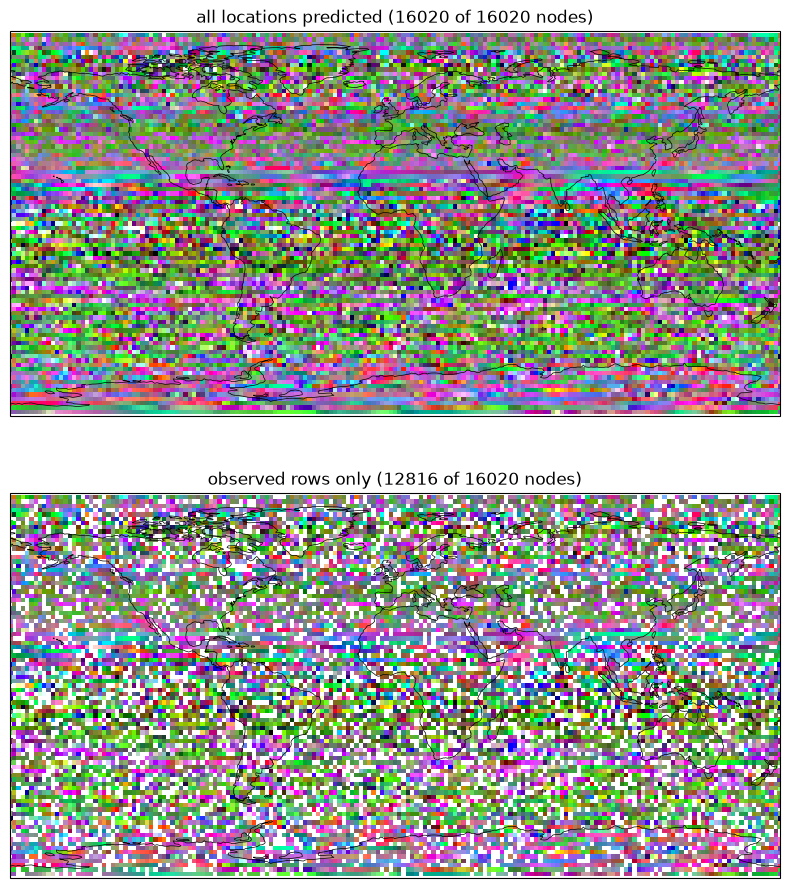

In [9]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

grid_index = np.empty(merged.num_nodes, dtype=np.int64)
grid_index[observed_mask] = np.arange(num_observed)
grid_index[withheld_mask] = np.arange(num_observed, merged.num_nodes)


def to_grid(graph_rows: torch.Tensor) -> np.ndarray:
    """Graph-order embedding rows back into the original lat/lon raster order."""
    values = np.full((grid_index.size, 3), np.nan, dtype=np.float32)
    values[grid_index] = graph_rows.detach().cpu().numpy()
    return values


full_grid = to_grid(all_locations)
observed_grid = np.full_like(full_grid, np.nan)
observed_grid[observed_mask] = full_grid[observed_mask]
print(
    "blank cells — full:",
    int(np.isnan(full_grid).any(axis=1).sum()),
    "| observed only:",
    int(np.isnan(observed_grid).any(axis=1).sum()),
)

# One scale from the full prediction, so a given node has the same colour in both panels.
scale = era5.colour_scale(full_grid, era5.PERCENTILE)

figure, axes = plt.subplots(
    2, 1, figsize=(12.0, 11.0), subplot_kw={"projection": ccrs.PlateCarree()}
)
for axis, (title, values, shown) in zip(
    axes,
    (
        ("all locations predicted", full_grid, merged.num_nodes),
        ("observed rows only", observed_grid, num_observed),
    ),
    strict=True,
):
    axis.set_global()
    era5.draw_globe(axis, latitudes, longitudes, values, scale=scale)
    axis.coastlines(linewidth=0.5)
    axis.set_title(f"{title} ({shown} of {merged.num_nodes} nodes)")
plt.show()


## Takeaways

|Fact|Why it matters|
|---|---|
|Merging unions locations|Added rows are unknown-featured either way|
|`y` holds the truth|The model never sees it as input; only the objective does|
|`input_mask` is provenance|Picks landmarks, senders and scorability; never masks the forward pass|
|`output_mask` chooses the prediction rows|Same graph, same inputs, different returned subset|

Next: **3-transfer-between-dates.ipynb** trains on this date and predicts on another.